# 시각화 모음

01·02 노트북의 그래프와 월별 Top N을 한곳에 모으고, 그래프마다 **무엇을 보여 주는지 · 읽는 법 · 알게 된 것**을 붙였다.
그래프는 원래 노트북과 같은 데이터로 다시 그린다. 보고서에 넣기 좋게 `reports/figures/`에 PNG로도 저장한다.
데이터는 모두 **제주 지역별 인기 장소**(티맵 내비 도착) 파일 하나에서 나온다.

| # | 그래프 | 원래 노트북 | 쓰는 파일 |
|---|---|---|---|
| 1 | 월별 행 수 | 01_load_clean | `data/raw/제주_지역별_인기_장소.csv` |
| 2 | 늘 인기 예시(`EXAMPLE_STEADY`) 월별 비중 | 01_load_clean | `place_month.csv`, `month_total.csv` |
| 3 | 제철 예시(`EXAMPLE_SEASONAL`) 월별 제철 지수 | 02_index | `si_place_month.csv` |
| 4 | 월별 제철 지수 Top N | 새로 만듦 | `si_place_month.csv` → `top5_by_month.csv` 저장 |

00 → 01 → 02를 먼저 실행해 두어야 한다. 옵션은 모두 `00_settings`에서 바꾼다.

> **"알게 된 것"의 숫자는 기준 연도 2024~2025년(현재 설정)으로 실행한 결과를 보고 쓴 것이다.** 설정을 바꾸면 그래프와 표는 자동으로 바뀌지만, 이 글은 다시 써야 한다.

In [1]:
from pathlib import Path
import platform
import pandas as pd
import matplotlib.pyplot as plt

%run settings.py
YEARS_LABEL = f"{BASE_YEARS[0]}~{BASE_YEARS[-1]}" if len(BASE_YEARS) > 1 else str(BASE_YEARS[0])
print(f"기준 연도 {YEARS_LABEL} · 예시 {EXAMPLE_STEADY}, {EXAMPLE_SEASONAL} · {VIEW_MONTH}월 · Top {TOP_N}")

RAW = Path("../data/raw")
PROC = Path("../data/processed")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

# 색과 선: 모든 그래프에 같은 규칙을 쓴다
SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # 계열 1·2·3 (색약 구분 검증된 순서)
PALE = "#c3c2b7"                                      # 강조하지 않는 막대
BAND = "#f0efec"                                      # 배경 띠

plt.rcParams.update({
    "font.family": {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic"),
    "axes.unicode_minus": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.axisbelow": True,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "axes.labelsize": 9,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "ytick.left": False, "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9,
})

MONTHS = [f"{m}월" for m in range(1, 13)]

def ref_lines(ax):
    """평소(1.0)와 제철 기준(SI_TH) 선. 이름은 그래프 오른쪽 바깥에 적는다."""
    ax.axhline(1.0, color=MUTED, lw=1)
    ax.axhline(SI_TH, color=INK2, lw=1, ls=(0, (4, 3)))
    tr = ax.get_yaxis_transform()   # x는 축 비율(1 = 오른쪽 끝), y는 데이터 값
    ax.text(1.01, 1.0, "평소 1.0", transform=tr, va="center", fontsize=8, color=MUTED)
    ax.text(1.01, SI_TH, f"제철 기준 {SI_TH}", transform=tr, va="center", fontsize=8, color=INK2)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    print("저장:", FIG / f"{name}.png")

기준 연도 2024~2025 · 예시 성산일출봉, 따라비오름 · 10월 · Top 5


---
## 1. 월별 행 수 — 빠진 달이 없는지 (01_load_clean)

**무엇을 보여 주나** 원본 파일(티맵 내비 도착)의 달마다 행 수다. 행 하나는 "그 달 도착 2건 이상인 목적지 하나"다.

**읽는 법** 선이 어느 달에 0으로 떨어지거나 갑자기 끊기면, 그 달 자료가 빠진 것이다. 회색 띠는 서비스용 기준 연도(`BASE_YEARS`) 밖이라 제철 지수 계산에 쓰지 않는 기간이다.

저장: ..\reports\figures\01_rows_per_month.png


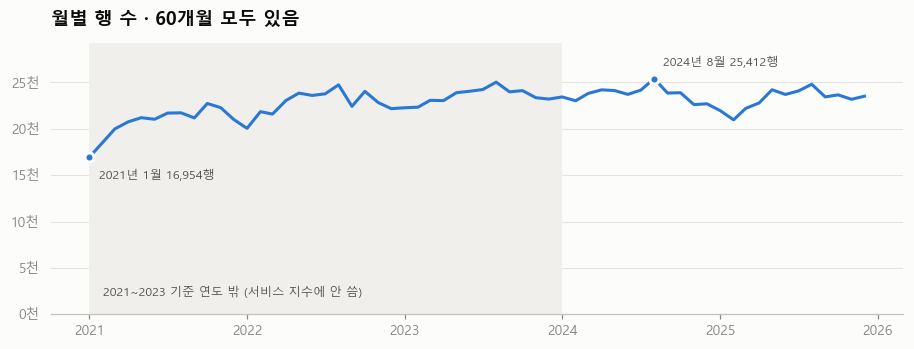

60개월, 빠진 달 0개


,min,mean,max
연도,,,
2021,16954,20759,22733
2022,20050,22830,24740
2023,22270,23550,25031
2024,22611,23746,25412
2025,20967,23210,24805


In [2]:
raw = pd.read_csv(RAW / "제주_지역별_인기_장소.csv", encoding="utf-8-sig", usecols=["주행일자(YYYYMM)"])
rows = raw.groupby("주행일자(YYYYMM)").size().rename("rows").reset_index()
rows.columns = ["ym", "rows"]
rows["date"] = pd.to_datetime(rows["ym"].astype(str), format="%Y%m")

first_year = rows["ym"].min() // 100
fig, ax = plt.subplots(figsize=(10, 3.2))
if first_year < min(BASE_YEARS):
    ax.axvspan(pd.Timestamp(f"{first_year}-01-01"), pd.Timestamp(f"{min(BASE_YEARS) - 1}-12-31"), color=BAND, lw=0)
    ax.text(pd.Timestamp(f"{first_year}-02-01"), 2000,
            f"{first_year}~{min(BASE_YEARS) - 1} 기준 연도 밖 (서비스 지수에 안 씀)", fontsize=8, color=INK2)
ax.plot(rows["date"], rows["rows"], color=BLUE)
for idx in [rows["rows"].idxmin(), rows["rows"].idxmax()]:
    r = rows.loc[idx]
    ax.plot(r["date"], r["rows"], "o", ms=6, color=BLUE, mec=SURFACE, mew=2)
    ax.annotate(f"{r['ym'] // 100}년 {r['ym'] % 100}월 {r['rows']:,}행", (r["date"], r["rows"]),
                xytext=(6, -14 if idx == rows["rows"].idxmin() else 8), textcoords="offset points", fontsize=8, color=INK2)
ax.set_ylim(0, rows["rows"].max() * 1.15)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}천")
ax.set_title(f"월별 행 수 · {len(rows)}개월 모두 있음")
save(fig, "01_rows_per_month")
plt.show()

print(f"{len(rows)}개월, 빠진 달 {(rows['ym'].max() // 100 - first_year + 1) * 12 - len(rows)}개")
rows.groupby(rows["ym"] // 100)["rows"].agg(["min", "mean", "max"]).round(0).astype(int).rename_axis("연도")

**알게 된 것**
- 2021-01 ~ 2025-12 **60개월이 모두 있고 빠진 달이 없다.** 행이 가장 적은 달은 2021년 1월(16,954행), 가장 많은 달은 2024년 8월(25,412행)이다.
- 연평균 행 수는 2021년 약 2.1만에서 2023~2025년 약 2.3~2.4만으로 늘었다. 코로나 시기(2021~22)에는 찾는 목적지 자체가 적었다.
- 서비스용 지수는 가장 최근 2년(2024~2025)으로 만든다. 2023년은 검증(2023~24로 만들고 2025로 맞히기)에만 쓴다.

---
## 2. 늘 인기 예시 월별 비중 (01_load_clean)

**무엇을 보여 주나** 예시 관광지(`EXAMPLE_STEADY`, 기본 성산일출봉) 도착이 그 달 제주 전체 도착에서 차지한 비중(%)이다. 기준 연도의 모든 달을 이어 그린다.

**읽는 법** 도착 수 그대로가 아니라 **비중**을 쓴다. 그래야 제주 전체 방문이 많은 달(성수기)에 덩달아 올라가는 효과가 빠지고, 이 관광지만의 계절 패턴이 남는다. 연한 띠는 해마다 7~8월이다.

저장: ..\reports\figures\02_steady_share.png


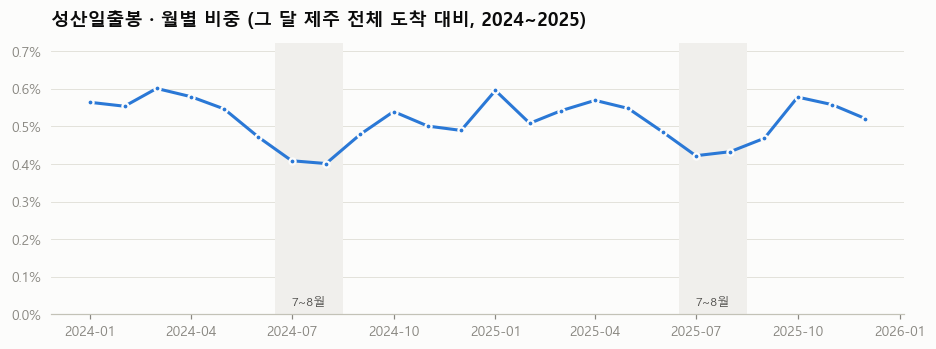

,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
연도,,,,,,,,,,,,
2024,0.56,0.55,0.60,0.58,0.55,0.47,0.41,0.40,0.48,0.54,0.50,0.49
2025,0.60,0.51,0.54,0.57,0.55,0.49,0.42,0.43,0.47,0.58,0.56,0.52


In [3]:
pm = pd.read_csv(PROC / "place_month.csv", encoding="utf-8-sig")
month_total = pd.read_csv(PROC / "month_total.csv", encoding="utf-8-sig")

name = EXAMPLE_STEADY
x = pm[pm["name"] == name].merge(month_total, on="ym")
x = x[(x["ym"] // 100).isin(BASE_YEARS)].copy()
x["share"] = x["arrive"] / x["total"] * 100
x["date"] = pd.to_datetime(x["ym"].astype(str), format="%Y%m")

fig, ax = plt.subplots(figsize=(10, 3.2))
for y in BASE_YEARS:
    ax.axvspan(pd.Timestamp(f"{y}-06-16"), pd.Timestamp(f"{y}-08-16"), color=BAND, lw=0)
    ax.text(pd.Timestamp(f"{y}-07-01"), x["share"].max() * 0.04, "7~8월", fontsize=8, color=INK2)
ax.plot(x["date"], x["share"], color=BLUE, marker="o", ms=4, mec=SURFACE, mew=1.5)
ax.set_ylim(0, x["share"].max() * 1.2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1f}%")
ax.set_title(f"{name} · 월별 비중 (그 달 제주 전체 도착 대비, {YEARS_LABEL})")
save(fig, "02_steady_share")
plt.show()

tbl = x.assign(연도=x["ym"] // 100, 월=x["ym"] % 100).pivot(index="연도", columns="월", values="share").round(2)
tbl.columns = MONTHS
tbl

**알게 된 것** (성산일출봉, 2024~2025)
- 성산일출봉은 1년 내내 제주 전체 도착의 약 0.40~0.60%를 차지한다. 절대 규모로는 늘 붐비는 곳이다.
- 그래도 **해마다 7~8월에 비중이 가장 낮다**(약 0.40~0.43%). 여름에는 사람들이 해수욕장으로 몰리기 때문이다. 두 해 모두 같은 모양이다.
- 그래서 02의 분류에서 성산일출봉은 **늘 인기**로 나오고, 가장 한산한 달은 7월이다(실제 도착 수 기준).
- 이 그래프는 "비중으로 보면 계절 패턴이 해마다 반복된다"는 방법의 출발점을 보여 준다.

---
## 3. 제철 예시 월별 제철 지수 (02_index)

**무엇을 보여 주나** 예시 관광지(`EXAMPLE_SEASONAL`, 기본 따라비오름)의 달마다 **제철 지수(SI)** = 그 달 비중 ÷ 12개월 평균 비중이다. 기준 연도의 같은 달끼리 평균 낸 값이다.

**읽는 법** 회색 실선(1.0)이 평소 수준이다. 점선(`SI_TH`)을 넘는 달이 제철 후보다. 파란 막대가 실제로 **제철로 분류된 달**이다. 분류되려면 기준선을 넘을 뿐 아니라, 기준 연도 중 `NEED_YEARS`년 이상 그 해에도 넘어야 한다. 기준 연도가 2년이면 **두 해 모두** 넘어야 한다.

저장: ..\reports\figures\03_seasonal_si.png


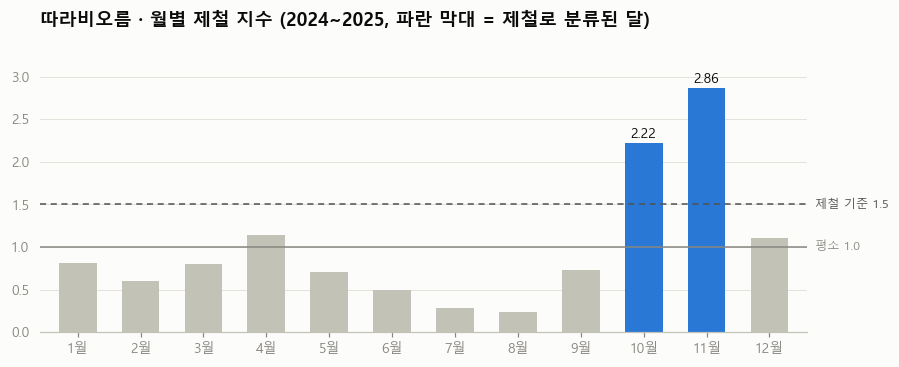

,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
si,0.82,0.6,0.8,1.14,0.71,0.5,0.28,0.24,0.73,2.22,2.86,1.1
hot_years,0,0,0,0,0,0,0,0,0,2,2,0
rank_pct,0.55,0.45,0.52,0.62,0.48,0.38,0.24,0.19,0.5,0.79,0.85,0.65
tourist_share,0.44,0.45,0.44,0.32,0.38,0.44,0.45,0.49,0.45,0.38,0.46,0.49
class,none,none,none,none,none,none,none,none,none,hidden,hidden,none


In [4]:
si = pd.read_csv(PROC / "si_place_month.csv", encoding="utf-8-sig")
name = EXAMPLE_SEASONAL
one = si[si["name"] == name].sort_values("m")
hot = one["class"].isin(["peak", "hidden"])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(one["m"], one["si"], width=0.6, color=[BLUE if h else PALE for h in hot])
ref_lines(ax)
for _, r in one[hot].iterrows():
    ax.text(r["m"], r["si"] + 0.06, f"{r['si']:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(1, 13), MONTHS)
ax.set_xlim(0.4, 12.6)
ax.set_ylim(0, one["si"].max() * 1.18)
ax.set_title(f"{name} · 월별 제철 지수 ({YEARS_LABEL}, 파란 막대 = 제철로 분류된 달)")
save(fig, "03_seasonal_si")
plt.show()

one.set_index("m")[["si", "hot_years", "rank_pct", "tourist_share", "class"]].round(2).T.set_axis(MONTHS, axis=1)

**알게 된 것** (따라비오름, 2024~2025)
- 따라비오름은 **10월(2.22)과 11월(2.86)**에 평소의 2~3배를 찾는다. 가을 억새 명소라는 상식과 맞는다.
- 두 달 모두 2년 내내 1.5를 넘어서(`hot_years` = 2) 한 해만 튄 게 아니다.
- 반대로 여름(7~8월)은 0.24~0.28로 평소의 4분의 1 수준이다.
- 10·11월 모두 **숨은 제철**(`hidden`)로 분류됐다. 방문은 많은 편(10월 상위 17%, 11월 상위 12%)이지만 관광객 비중(10월 0.38, 11월 0.46)이 그 달 하위 30%라 "도민이 주로 찾는 곳"에 들기 때문이다. 상세 화면에서는 "도민도 찾는 곳" 배지가 붙는다.
- 02의 검증에서 따라비오름은 "알려진 제철 관광지" 20곳 중 하나로, 예상 월(10~11월)을 정확히 맞혔다.

---
## 4. 월별 제철 지수 Top N (02_index 결과로 새로 만듦)

**무엇을 보여 주나** 달마다 제철 지수(SI)가 가장 높은 관광지 `TOP_N`곳(기본 5곳)이다. 서비스용 결과(`si_place_month.csv`)를 쓴다.

**순위를 매기는 범위** 그 달 **제철로 분류된 곳**(제철 명소 + 숨은 제철)만 본다. 분석 대상 전체에서 SI만으로 뽑으면 한 해만 튄 곳이나, 평소 방문이 거의 없어 조금만 늘어도 SI가 크게 뛰는 곳이 섞인다. 제철 분류는 "기준 연도 중 `NEED_YEARS`년 이상 기준 이상"을 이미 거쳤다.

**읽는 법** 12개 칸이 1~12월이다. 막대 길이가 SI이고, 모든 칸의 가로축 눈금이 같아서 달끼리 바로 비교할 수 있다. 파랑은 제철 명소(이번 달 인기), 주황은 숨은 제철(인기 밖이거나 도민 위주)이다. 점선은 제철 기준이다.

In [5]:
TYPE_LABEL = {"peak": "제철 명소", "hidden": "숨은 제철"}

top = (si[si["class"].isin(TYPE_LABEL)]
       .sort_values(["m", "si"], ascending=[True, False])
       .groupby("m").head(TOP_N).copy())
top["rank"] = top.groupby("m").cumcount() + 1
top["type"] = top["class"].map(TYPE_LABEL)

cols = ["m", "rank", "name", "emd", "cat", "si", "hot_years", "arrive", "type"]
top[cols].round(2).to_csv(PROC / "top5_by_month.csv", index=False, encoding="utf-8-sig")
print("저장:", PROC / "top5_by_month.csv", f"{len(top)}행 (Top {TOP_N})")

# 한눈에 보는 표: 행 = 월, 열 = 순위, 값 = 이름 (SI)
table = top.assign(cell=top["name"] + " (" + top["si"].round(2).astype(str) + ")").pivot(index="m", columns="rank", values="cell")
table.index = [f"{m}월" for m in table.index]
table.columns = [f"{r}위" for r in table.columns]
table

저장: ..\data\processed\top5_by_month.csv 60행 (Top 5)


,1위,2위,3위,4위,5위
1월,삼다체육공원 (7.29),제주동백수목원 (5.44),동백포레스트 (5.05),트로이테마농원 (3.91),위미동백나무군락 (3.49)
2월,성산유채꽃밭 (4.06),유채꽃사진촬영소 (3.52),산방산유채꽃밭 (2.9),봉봉감귤체험농장 (2.9),위미동백나무군락 (2.13)
3월,장전리왕벚꽃거리 (7.09),엉덩물계곡 (6.8),녹산로유채꽃도로 (5.54),대왕수천예래생태공원 (5.13),성산유채꽃밭 (5.06)
4월,녹산로유채꽃도로 (5.59),대왕수천예래생태공원 (5.38),장전리왕벚꽃거리 (4.87),가파도 (4.36),오라CC입구벚꽃길 (3.46)
5월,와흘메밀마을/체험힐링센터 (5.13),오라동메밀밭 (3.8),가파도 (2.44),서귀포칠십리시공원 (1.97),보목포구 (1.81)
6월,답다니수국밭 (10.51),종달리수국길 (9.01),혼인지 (7.25),오라동메밀밭 (2.51),엉또폭포 (2.41)
7월,강정천 (3.73),강정천유원지 (3.53),세기알해변 (3.13),태웃개 (3.12),돈내코계곡 (3.1)
8월,강정천 (5.36),강정천유원지 (5.11),도리빨 (4.44),태웃개 (3.82),돈내코계곡 (3.72)
9월,도리빨 (3.05),자구리담수욕장 (1.91),구두미포구 (1.9),포도뮤지엄 (1.88),제주문학관 (1.78)
10월,와흘메밀마을/체험힐링센터 (3.55),어음리억새군락지 (2.99),산굼부리 (2.87),오라동메밀밭 (2.48),새별오름 (2.27)


저장: ..\reports\figures\04_top5_by_month.png


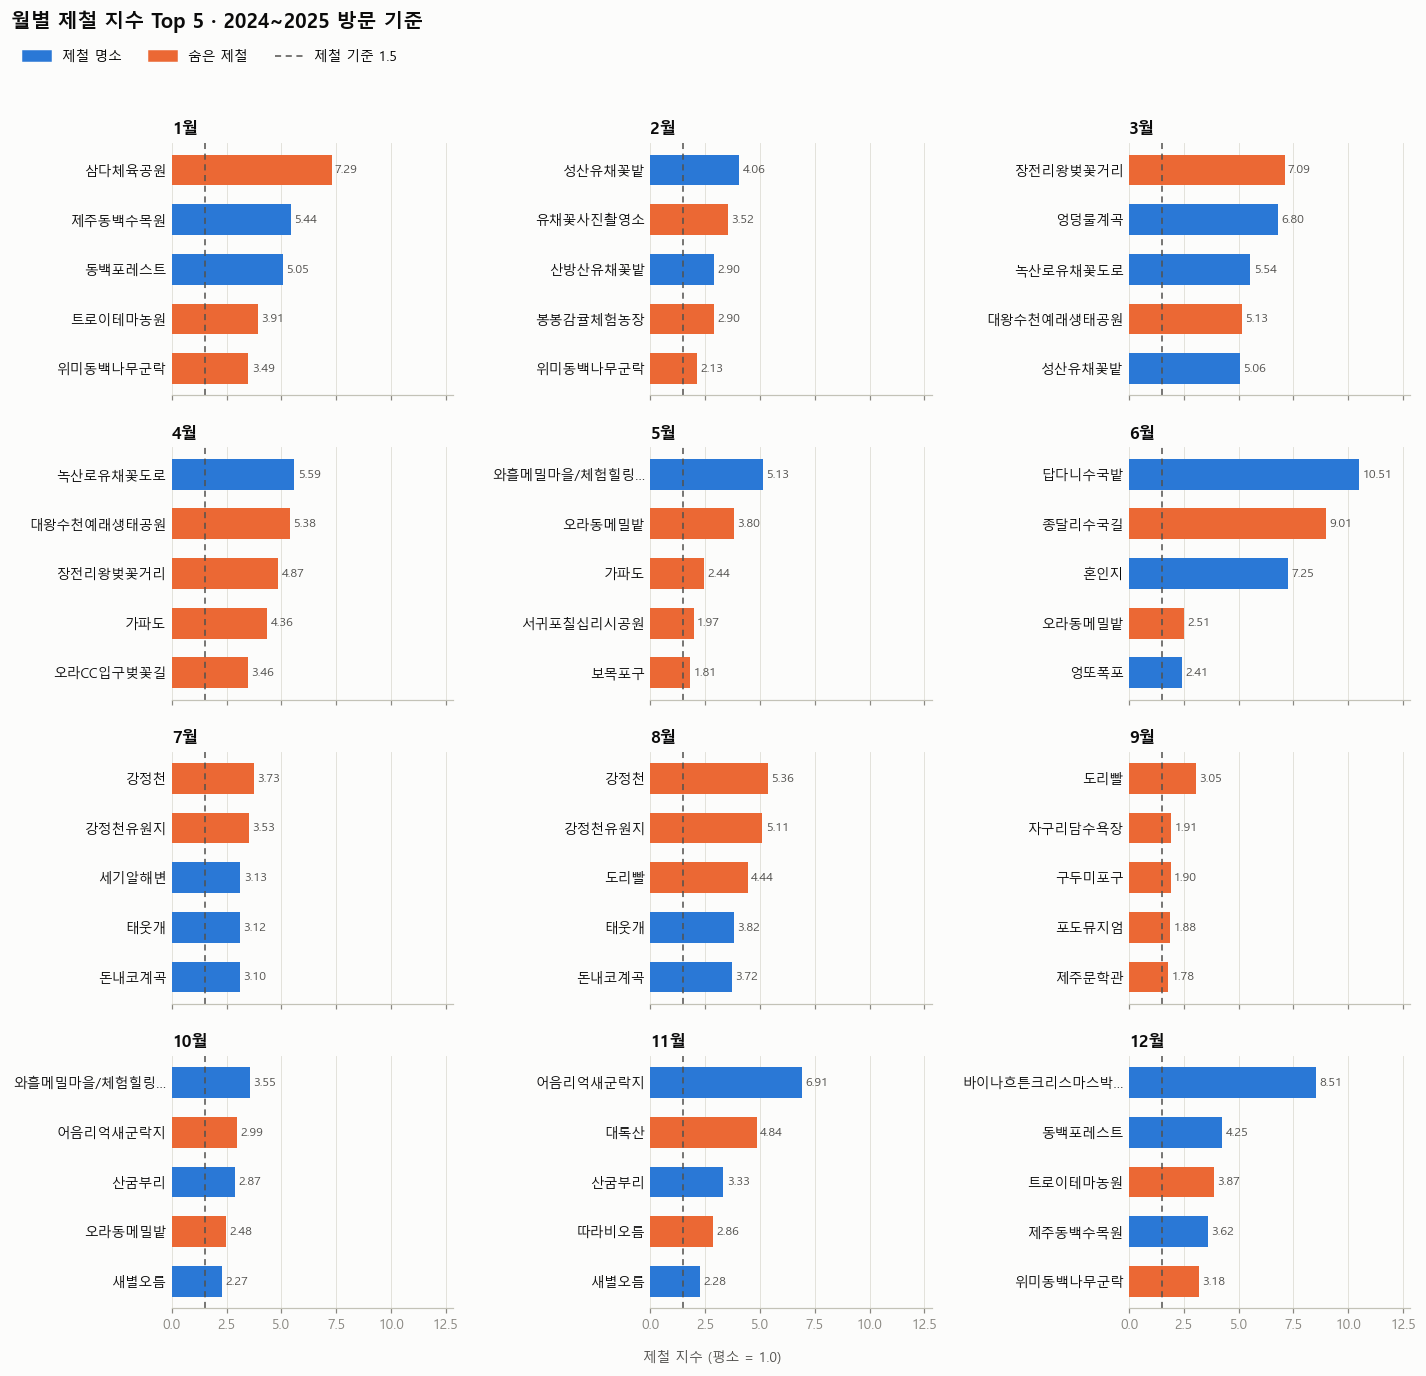

In [6]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

TYPE_COLOR = {"peak": BLUE, "hidden": ORANGE}

def short(name, n=12):   # 긴 이름은 칸에 맞게 줄인다 (전체 이름은 위 표에 있다)
    return name if len(name) <= n else name[: n - 1] + "…"

xmax = top["si"].max() * 1.22
fig, axes = plt.subplots(4, 3, figsize=(13, 2.5 + TOP_N * 2), sharex=True)
for ax, m in zip(axes.flat, range(1, 13)):
    d = top[top["m"] == m].sort_values("rank", ascending=False)   # 1위가 맨 위로 오게
    y = range(len(d))
    ax.barh(y, d["si"], height=0.62, color=d["class"].map(TYPE_COLOR))
    for yi, v in zip(y, d["si"]):
        ax.text(v + xmax * 0.012, yi, f"{v:.2f}", va="center", fontsize=8, color=INK2)
    ax.axvline(SI_TH, color=INK2, lw=1, ls=(0, (4, 3)))
    ax.set_yticks(list(y), [short(n) for n in d["name"]])
    ax.tick_params(axis="y", labelcolor=INK, labelsize=9, length=0)
    ax.grid(False)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_xlim(0, xmax)
    ax.set_title(f"{m}월", fontsize=11, pad=6)

legend = [Patch(color=BLUE, label="제철 명소"), Patch(color=ORANGE, label="숨은 제철"),
          Line2D([], [], color=INK2, lw=1, ls=(0, (4, 3)), label=f"제철 기준 {SI_TH}")]
fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(0.01, 0.975), ncols=3)
fig.suptitle(f"월별 제철 지수 Top {TOP_N} · {YEARS_LABEL} 방문 기준", x=0.01, y=0.995, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.supxlabel("제철 지수 (평소 = 1.0)", fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.955), h_pad=1.6, w_pad=2.0)
save(fig, "04_top5_by_month")
plt.show()

**알게 된 것** (Top 5, 2024~2025)
- **제주의 계절 달력이 그대로 나온다.** 1·12월 동백(제주동백수목원, 동백포레스트, 위미동백나무군락), 2월 유채, 3~4월 벚꽃·유채(장전리왕벚꽃거리, 녹산로유채꽃도로), 5월 메밀·청보리(오라동메밀밭, 가파도), 6월 수국(답다니수국밭, 종달리수국길, 혼인지), 7~8월 계곡·용천수(강정천, 정모시쉼터, 생수천생태문화공원), 10~11월 억새·감귤(어음리억새군락지, 산굼부리, 도련감귤나무숲), 12월 크리스마스(바이나흐튼크리스마스박물관)다.
- 가장 강한 제철은 **6월 답다니수국밭(10.51)**, 11월 천아계곡(10.26), 6월 종달리수국길(9.01), 12월 바이나흐튼크리스마스박물관(8.51)이다. 한 달에 몰리는 꽃·단풍·행사 명소다.
- Top 5 60자리 중 **숨은 제철이 41자리, 제철 명소가 19자리**다. 7~9월은 5곳 모두 숨은 제철이다. SI가 높은 곳은 평소 방문이 적은 곳이 많아서, "덜 알려졌지만 지금 가면 좋은 곳"을 보여 준다는 서비스 취지와 맞는다.
- **9월은 제철이 약한 달**이다. 1위도 3.05뿐이고, 포구·담수욕장처럼 여름이 끝나 가는 곳이 대부분이다. 여름과 가을 사이에 낀 달이라 "늘 인기" 쪽을 더 보여 주는 게 나을 수 있다.

**확인이 필요한 곳** (데이터 문제일 수 있음)
- **같은 곳이 두 이름**으로 잡히는 문제가 있다. 기준 연도가 2023~2025일 때는 `와흘메밀마을/체험힐링센터`와 `와흘메밀마을 체험힐링센터`가 5월에 둘 다 나왔다. 2024~2025에서는 뒤쪽이 월평균 4건뿐이라 분석 대상에서 빠졌지만, 문제 자체는 남아 있어서 01에서 합치는 처리가 필요하다.
- 관광지로 추천하기에 어색한 이름이 있다. `삼다체육공원`(1월), `정석항공관`(4월, 근처 가시리 유채꽃길 때문일 가능성), `월평포구/공사중(…)`(9월), `도시해녀`, `베니스랜드`(5월). 웹에 올리기 전에 직접 보고 뺄지 정한다.

---
### 정리 (2024~2025 기준)

| 그래프 | 한 줄 요약 |
|---|---|
| 1. 월별 행 수 | 60개월 모두 있고, 2023~25년은 해마다 안정적이다 |
| 2. 성산일출봉 비중 | 비중으로 보면 계절 패턴(여름에 낮음)이 해마다 반복된다 |
| 3. 따라비오름 SI | 10·11월이 평소의 2.2~2.9배라 제철로 잡히고, 두 해 모두 같다 |
| 4. 월별 Top 5 | 동백·유채·벚꽃·수국·계곡·억새로 이어지는 계절 달력이 나오고, 대부분 숨은 제철이다 |